# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: Gate 2 = GO / Gate 3 = NA means the manifold is non-branching, so the
branching-only `04_correlation` and `05_modules` notebooks are **not** produced — this
unconditional expression notebook follows signatures directly, per spec §6.)*

Puram 2017 overlays SNAI1 (root) and ZEB1 (terminus) as its two EMT-TFs. Per the
derive-don't-inherit mandate we do **not** inherit that pair: we score a candidate EMT-TF panel
— the canonical Snail/Zeb/Twist factors **plus the mesenchymal / neural-crest FOXC and PRRX
families** (spec §6, 03_eval lesson 5) — along *this* trajectory (pSom-high origin → Gast/Crest
terminus). VIM is a mesenchymal marker, **not** a transcription factor, and is excluded. Factors
below a 3% detectable-expression floor are dropped as too sparse to overlay.

**What the data show (derived, honest).** Every expressed EMT-TF here leans toward the
somitogenesis-high **root/origin** rather than splitting into a root-vs-terminus pair (all rho vs
pseudotime ≤ 0, FOXC1/SNAI2/FOXC2 all root-enriched): the EMT-TF programme concentrates at the
pSom origin and *depletes* toward the Gast/Crest terminus — consistent with the non-branching,
inverse-gradient geometry (there is no distinct terminal EMT-TF to mark). We therefore overlay
the **two most-informative expressed factors by abundance** — **FOXC1** (46% expressing, the
dominant EMT-TF, root-enriched — the same root-end mesenchymal factor surfaced on Kürten) and
**SNAI2** (9%, the next most-expressed canonical factor) — rather than forcing a spurious
terminus factor. Deliverable: `expression.pdf` (categorical overlay of thresholded expressers on
a grey manifold).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import logging; logging.getLogger('harmonypy').setLevel(logging.WARNING)
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 635 | pseudotime range 0.0 -> 7.52


### Score the EMT-TF panel and select the informative factors (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs
late (terminus) pseudotime tercile, and Spearman correlation with pseudotime (negative = root-
enriched, positive = terminus-enriched). Factors below a 3% expression floor are too sparse to
overlay. Because every expressed factor here is root-leaning (no genuine terminus TF), we select
the **two most-abundant expressed factors** for the overlay rather than forcing a root/terminus
pair — the honest readout for this inverse-gradient manifold.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('panel genes present in matrix:', present)
print('panel genes absent (dropped):', [g for g in panel if g not in adata.var_names])
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'root-enriched', 'terminus-enriched')
print(df.sort_values('rho_vs_t').to_string(index=False))
ok = df[df.frac_expr > 0.03].sort_values('frac_expr', ascending=False)
tf1, tf2 = ok.iloc[0]['TF'], ok.iloc[1]['TF']          # two most-abundant expressed EMT-TFs
end = dict(zip(df.TF, df.end))
print(f'\nexpressed EMT-TFs (>3%): {ok.TF.tolist()}')
print(f'selected for overlay (top-2 by abundance): {tf1} ({end[tf1]}, {ok.iloc[0].frac_expr:.0%}) '
      f'& {tf2} ({end[tf2]}, {ok.iloc[1].frac_expr:.0%})')
print('note: all expressed EMT-TFs are root-enriched (rho<=0) -> EMT-TF programme sits at the pSom origin, depletes toward terminus')

panel genes present in matrix: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'FOXC1', 'FOXC2', 'PRRX2']
panel genes absent (dropped): ['TWIST1', 'TWIST2', 'PRRX1']
   TF  frac_expr  mean_early  mean_late  rho_vs_t           end
FOXC2      0.019       0.039      0.002    -0.142 root-enriched
FOXC1      0.461       0.510      0.374    -0.124 root-enriched
 ZEB2      0.019       0.018      0.005    -0.071 root-enriched
SNAI2      0.090       0.089      0.059    -0.061 root-enriched
SNAI1      0.008       0.004      0.000    -0.022 root-enriched
PRRX2      0.065       0.051      0.030    -0.019 root-enriched
 ZEB1      0.030       0.021      0.018    -0.002 root-enriched

expressed EMT-TFs (>3%): ['FOXC1', 'SNAI2', 'PRRX2']
selected for overlay (top-2 by abundance): FOXC1 (root-enriched, 46%) & SNAI2 (root-enriched, 9%)
note: all expressed EMT-TFs are root-enriched (rho<=0) -> EMT-TF programme sits at the pSom origin, depletes toward terminus


### EMT-TF expression overlay (deliverable `expression.pdf`)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Categorical overlay of
thresholded expressers on a grey manifold (**not** a continuous single-gene colormap — spec §6).
Draw order is set by abundance (more widely-expressed factor first, sparser on top) so neither
marker is occluded. Each factor is thresholded at the upper quartile of expression among its
expressing cells, so only the strongest expressers show.

overlay thresholds (upper quartile among expressers): {'FOXC1': 1.222, 'SNAI2': 1.038} | cells shown: {'FOXC1': 73, 'SNAI2': 14}
FOXC1: 46.1% expressing; 73 shown (upper quartile), mean pseudotime of shown cells = 0.43 (all cells = 0.51)
SNAI2: 9.0% expressing; 14 shown (upper quartile), mean pseudotime of shown cells = 0.36 (all cells = 0.51)
saved expression.pdf | EMT-TFs shown: FOXC1 + SNAI2


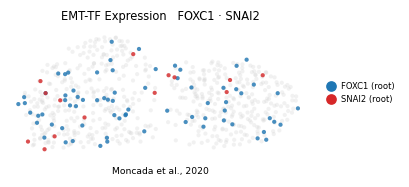

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf1, tf2]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf1, tf2]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [tf1, tf2]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [tf1, tf2]})
order = sorted([tf1, tf2], key=lambda g: -int(sel[g].sum()))
colors = {tf1:'tab:blue', tf2:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {tf1} · {tf2}', size=7.5)
ax.text(.5,-.14,'Moncada et al., 2020', ha='center', transform=ax.transAxes, size=6)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],marker='o',ls='',color=colors[tf1],label=f'{tf1} ({end[tf1].split("-")[0]})'),
                   Line2D([0],[0],marker='o',ls='',color=colors[tf2],label=f'{tf2} ({end[tf2].split("-")[0]})')],
          frameon=False, loc='center left', bbox_to_anchor=(1.02,.5), fontsize=5.5, handletextpad=.2)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [tf1, tf2]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf | EMT-TFs shown:', tf1, '+', tf2)